<a href="https://colab.research.google.com/github/SattikBhaumik/CS156/blob/main/CS156_Session_18.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

### Question 1: Autoencoder Intro (2)

In 150 words or less, describe the "nonlinear dimensionality reduction" property of autoencoders. Does this make them more or less expressive than PCA?

Answer here:

**Prompt**: In 150 words or less, describe the "nonlinear dimensionality reduction" property of autoencoders. Does this make them more or less expressive than PCA? PROMPT: The response has to be a good high-level explanation of how an Autoencoder works.
- **Output**: An autoencoder is a neural network that learns to compress high-dimensional data into a lower-dimensional representation and then reconstruct the original data. It consists of two components: an encoder, which maps the input into a compressed representation called the latent space, and a decoder, which reconstructs the input from this representation. During training, the network minimizes reconstruction error, learning to preserve important features of the data. Unlike PCA, which performs linear dimensionality reduction by projecting data onto orthogonal principal components, autoencoders use nonlinear activation functions to learn complex, nonlinear relationships. This allows them to capture curved structures and patterns in data that PCA cannot represent effectively. Therefore, autoencoders are potentially more expressive than PCA, as they can learn both linear and nonlinear representations. However, this greater flexibility requires more training data and computational resources and increases the risk of overfitting.

**Prompt**: In 150 words or less, describe the "nonlinear dimensionality reduction" property of autoencoders. Does this make them more or less expressive than PCA? PROMPT: The response has to be a good step-by-step explanation of the mechanism that produces a compressed representation of the input.
- **Output**: An autoencoder performs nonlinear dimensionality reduction by learning a compressed representation of high-dimensional input data through three steps:
Encoding: The encoder transforms the input through successive neural network layers using weighted transformations and nonlinear activation functions (e.g., ReLU). These functions allow the network to learn complex, nonlinear relationships between features.
Bottleneck: The encoder maps the input into a lower-dimensional latent space, forcing the network to retain the most informative features while discarding redundant information.
Decoding: The decoder reconstructs the original input from the compressed representation. During training, the network minimizes reconstruction error using backpropagation, improving the quality of the learned representation.
Autoencoders are more expressive than PCA because PCA performs only linear dimensionality reduction, projecting data onto orthogonal directions of maximum variance. In contrast, nonlinear autoencoders can learn curved, complex low-dimensional manifolds that PCA cannot represent. However, this greater expressiveness does not guarantee better generalization.

### Core Question 2: Autoencoding Handwritten Digits (3)

In this question, we revisit the neural network code from the Backpropagation lesson, and rework it to become an autoencoder!

In [ ]:
%pip install jax[cpu]
%pip install optax

In [ ]:
import jax
import numpy as np
import jax.numpy as jnp
import optax

from sklearn import datasets
from matplotlib import pyplot as plt

In [ ]:
digits = datasets.load_digits()
x_data, y_data = digits['data'], digits['target']

x_data = x_data / 16 # from 0 to 16, to 0 to 1 range

Let's visualize one of the data points in this dataset:

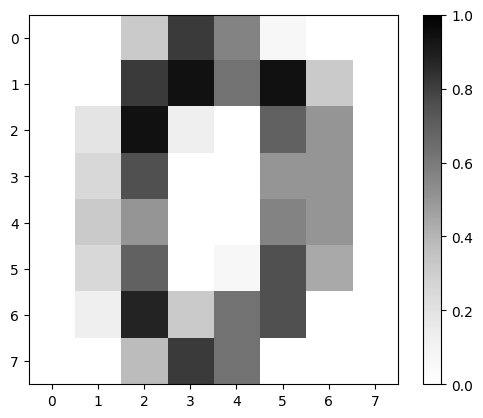

In [ ]:
plt.imshow(x_data[0].reshape(8, 8), cmap="Greys", vmin=0, vmax=1)
plt.colorbar()
plt.show()

Now, we set up the autoencoder: it's just another neural network, where *halfway through the network* we have a "bottleneck layer". The bottleneck is *significantly* smaller than the inputs *and* the rest of the network:

* The input is 64 dimensional
* The hidden layers are 8 dimensional
* The bottleneck is only 2 dimensional. That is, *all* subsequent layers past the bottleneck will only receive whatever information is "compressed" into this 2D bottleneck.

In [ ]:
input_dim = 64
hidden_dim = 8
bottleneck_dim = 2
output_dim = input_dim

params = {
    "layer_1": {
        "W": np.random.normal(size=(input_dim, hidden_dim)) / np.sqrt(input_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_2": {
        "W": np.random.normal(size=(hidden_dim, hidden_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_3": {
        "W": np.random.normal(size=(hidden_dim, bottleneck_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(bottleneck_dim,)),
    },
    "layer_4": {
    "W": np.random.normal(size=(bottleneck_dim, hidden_dim)) / np.sqrt(bottleneck_dim),
    "b": np.zeros(shape=(hidden_dim,)),
    },
    "layer_5": {
        "W": np.random.normal(size=(hidden_dim, output_dim)) / np.sqrt(hidden_dim),
        "b": np.zeros(shape=(output_dim,)),
    },
}

# Pay close attention to this function for the next question.
def predict_fn(params, X):
    X0 = X
    # remember, * is an elementwise multiply, whereas @ is a matrix multiply.
    X1 = jax.nn.relu(X0 @ params["layer_1"]["W"] + params["layer_1"]["b"])
    X2 = jax.nn.relu(X1 @ params["layer_2"]["W"] + params["layer_2"]["b"])
    X3 = X2 @ params["layer_3"]["W"] + params["layer_3"]["b"]
    X4 = jax.nn.relu(X3 @ params["layer_4"]["W"] + params["layer_4"]["b"])
    X5 = jax.nn.sigmoid(X4 @ params["layer_5"]["W"] + params["layer_5"]["b"])
    return {'reconstruct': X5, 'bottleneck': X3}

def loss_fn(params, X):
    reconstruct_X = predict_fn(params, X)['reconstruct']
    loss = -(X * jnp.log(reconstruct_X) + (1 - X) * jnp.log(1 - reconstruct_X))
    return jnp.mean(loss)

**Questions 2a**: Answer the following
* How many layers does this network have?
* Which layer is the "bottleneck layer"?
* How many layers does the encoder (the layers before bottleneck) and the decoder (the layers after the bottleneck) have?
* Why are they called "encoder" and "decoder"?
* Why are we returning `{'reconstruct': X5, 'bottleneck': X3}`? Why are these two values special?

Answer here:
- This network has 5 layers
- Layer 3 is the bottleneck later (or X3)
- The encoder has two layers (Layers 1 and 2) before the bottleneck (Layer 3) and the decoder has two layers after the bottleneck (Layers 4 and 5)
- The layers 1 and 2 are called encoder since they encode/compress the input into a space that contains the most relevant features which are then used by the decoder to reconstruct the initial input.
- The `reconstruct`: X5 means the final output layer of 64 dimensions using which we can check how well the original input was reconstructed (we can compute the difference between the two). The `bottleneck`: X3 means the bottleneck layer of 2 dimensions which contains the features of the original input that were compressed into the new space (64 dim --> 2 dim) that X3 corresponds to. The bottleneck layers tells us which are the most relevant/important features.

Now, let's train this model!

In [ ]:
step_size = 0.01
total_steps = 3000

# We use an optimizer called Adam here.
# We won't go into detail, but think of it as "fast gradient descent"
optimizer = optax.adam(1e-3)
opt_state = optimizer.init(params)

grad_loss_fn = jax.grad(loss_fn)
grad_loss_fn = jax.jit(grad_loss_fn)

for i in range(total_steps):
    idxs = np.random.randint(low=0, high=x_data.shape[0], size=32)
    x_batch = x_data[idxs]
    # Remember, we compute gradients of the *first* argument, which is params.
    grad = grad_loss_fn(params, x_batch)
    update, opt_state = optimizer.update(grad, opt_state)
    params = optax.apply_updates(params, update)

    # We print the loss every 100 steps
    if i % 100 == 0:
        loss_val = loss_fn(params, x_data)
        print("Step:", i, "Loss:", loss_val)

Step: 0 Loss: 0.6915803
Step: 100 Loss: 0.57889956
Step: 200 Loss: 0.44659054
Step: 300 Loss: 0.42045444
Step: 400 Loss: 0.41426694
Step: 500 Loss: 0.41059673
Step: 600 Loss: 0.40769628
Step: 700 Loss: 0.40504813
Step: 800 Loss: 0.40251407
Step: 900 Loss: 0.40012434
Step: 1000 Loss: 0.39781222
Step: 1100 Loss: 0.39559913
Step: 1200 Loss: 0.39350566
Step: 1300 Loss: 0.39177942
Step: 1400 Loss: 0.39042225
Step: 1500 Loss: 0.38868514
Step: 1600 Loss: 0.3875651
Step: 1700 Loss: 0.38626227
Step: 1800 Loss: 0.3851741
Step: 1900 Loss: 0.38423732
Step: 2000 Loss: 0.38345176
Step: 2100 Loss: 0.38254815
Step: 2200 Loss: 0.38193664
Step: 2300 Loss: 0.38113824
Step: 2400 Loss: 0.38042283
Step: 2500 Loss: 0.3797248
Step: 2600 Loss: 0.37931922
Step: 2700 Loss: 0.3786158
Step: 2800 Loss: 0.37814158
Step: 2900 Loss: 0.3776489


Now, this network has two outputs: `reconstruct`, which is an attempt at reconstructing the original input, and `bottleneck`, which is the output of the bottleneck layer itself. Let's see the reconstruction vs the original:

In [ ]:
predict_vals = predict_fn(params, x_data)

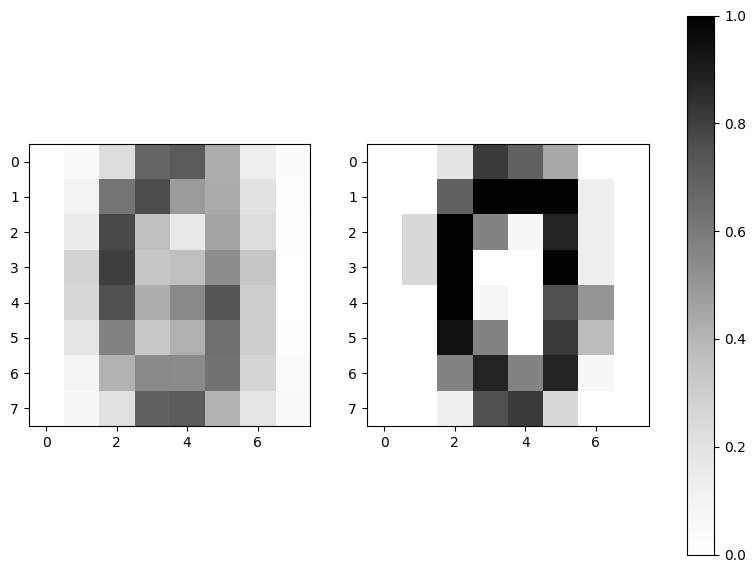

In [ ]:
EXAMPLE_NUMBER = 20

fig, ax = plt.subplots(nrows=1, ncols=2, figsize=(10, 7))
img0 = ax[0].imshow(predict_vals['reconstruct'][EXAMPLE_NUMBER].reshape(8, 8), vmin=0, vmax=1, cmap="Greys")
img1 = ax[1].imshow(x_data[EXAMPLE_NUMBER].reshape(8, 8), vmin=0, vmax=1, cmap="Greys")
fig.colorbar(img0, ax=ax)
plt.show()

**Question 2b**: `x_data` has 1797 examples. Try  different values of `EXAMPLE_NUMBER` within that range to see how well the model reconstructs the original. Qualitatively, how good are these reconstructions, and in what ways are they flawed?

Answer here:

Most of the reconstructions are pretty good. I can clearly read what the digits mean like 3, 1, 2, 7, 6 but I would not say that they are clear at the first instance. They are like smeared especially the digits like 6 and 3 which have curvilinear features in them (even though there was one 3 using example_number 70 which showed very good reconstructed 3.

We can also extract the bottleneck values. Since the layer is 2 dimensional, we can directly plot it as a scatter plot!

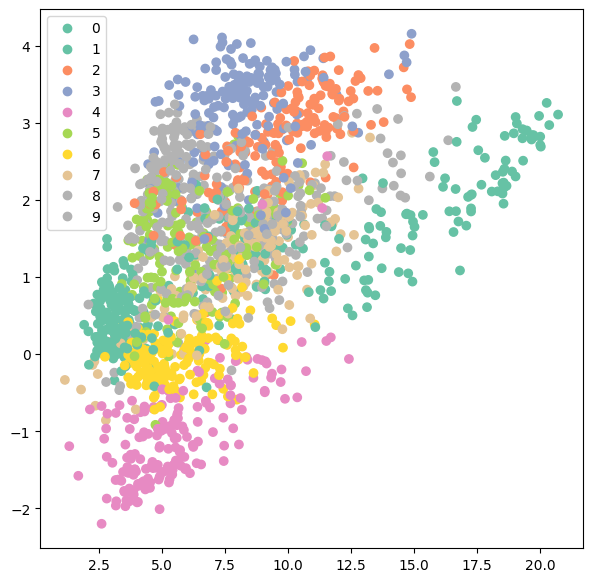

In [ ]:
fig, ax = plt.subplots(figsize=(7, 7))
scatter = ax.scatter(predict_vals['bottleneck'][:, 0], predict_vals['bottleneck'][:, 1], c=y_data, cmap="Set2")
ax.legend(handles=scatter.legend_elements()[0], labels=list(digits['target_names']))
plt.show()

**Questions 2c:**

1. What behavior do you see in the plot above? Are bottleneck vectors of images of the same digit closer or further apart?
2. What can you say about this plot, given that the model *never* sees the labels during training (it purely reconstructs every digit image as provided, with no additional information about what class it belongs to)?

Answer here:

1. The bottleneck vectors form groups of clusters with some having greater variance than others. Some of them come together around the top-left region of the center of the plot.

2. I would say that the plot shows a pretty good clustering given that the model never sees the labels during training. Without seeing any information about class, the model is able to figure out the similarities at its first attempt of training even though they are not of that great use in the real world yet.

### Extension Question 3: A better autoencoder (4)

In the code cells below:
* Modify the code above, to extend the model's encoder and decoders from 2 layers to 3 layers each. (This means updating both the forward pass, and the weight initialization)
* Rerun training with this modified model, and record the loss you obtain. Is it better than in question 2?

You may copy any of the code from the cells above as needed, and modify them.

In [ ]:
# I came across two errors which I corrected using claude suggestions
input_dim = 64
hidden_dim = 8
bottleneck_dim = 2
output_dim = input_dim

# 3 hidden layers before and after the bottleneck
layer_dims = [64, 8, 8, 8, 2, 8, 8, 8, 64]

# Claude suggestion to run a for-loop
# instead of individually listing the layers
params = {}

for i in range(len(layer_dims) - 1):
    in_dim = layer_dims[i]
    out_dim = layer_dims[i + 1]

    params[f"layer_{i+1}"] = {"W": np.random.normal(size=(in_dim, out_dim)) / np.sqrt(in_dim),"b": np.zeros(out_dim)}

# previous code with some claude suggestions i implemented
# during error correction
def predict_fn(params, X):
    X_current = X
    bottleneck = None
    # for loop instead of individual variable declaration
    for i in range(1, 9):
        layer = params[f"layer_{i}"]
        X_current = X_current @ layer["W"] + layer["b"]
        # i don't like this approach but could not think of anything better
        # I will try to find a better way to code this later
        # and for assignments
        if i == 4:
            bottleneck = X_current
        elif i == 8:
            X_current = jax.nn.sigmoid(X_current)
        else:
            X_current = jax.nn.relu(X_current)

    return {
        "reconstruct": X_current,
        "bottleneck": bottleneck
    }

def loss_fn(params, X):
    reconstructed = predict_fn(params, X)["reconstruct"]
    # clipping with a short finite range
    reconstructed = jnp.clip(reconstructed, 1e-7, 1 - 1e-7)
    loss = -(X * jnp.log(reconstructed) + (1 - X) * jnp.log(1 - reconstructed))
    return jnp.mean(loss)


In [ ]:
total_steps = 3000

# We use an optimizer called Adam here.
# We won't go into detail, but think of it as "fast gradient descent"
optimizer = optax.adam(1e-3)
opt_state = optimizer.init(params)

grad_loss_fn = jax.grad(loss_fn)
grad_loss_fn = jax.jit(grad_loss_fn)

for i in range(total_steps):
    idxs = np.random.randint(low=0, high=x_data.shape[0], size=32)
    x_batch = x_data[idxs]

    # Remember, we compute gradients of the *first* argument, which is params.
    grad = grad_loss_fn(params, x_batch)
    update, opt_state = optimizer.update(grad, opt_state)
    params = optax.apply_updates(params, update)

    # We print the loss every 100 steps
    if i % 100 == 0:
        print("Step:", i, "Loss:", loss_fn(params, x_data))

# claude suggestion
final_loss = loss_fn(params, x_data)
print("Final loss:", float(final_loss))

Step: 0 Loss: 0.70330054
Step: 100 Loss: 0.56512284
Step: 200 Loss: 0.46326938
Step: 300 Loss: 0.43125615
Step: 400 Loss: 0.42189634
Step: 500 Loss: 0.41962022
Step: 600 Loss: 0.4180358
Step: 700 Loss: 0.41702685
Step: 800 Loss: 0.4163352
Step: 900 Loss: 0.4154737
Step: 1000 Loss: 0.41491294
Step: 1100 Loss: 0.4143535
Step: 1200 Loss: 0.41360798
Step: 1300 Loss: 0.41254666
Step: 1400 Loss: 0.41185498
Step: 1500 Loss: 0.41043383
Step: 1600 Loss: 0.40853533
Step: 1700 Loss: 0.40687257
Step: 1800 Loss: 0.40419593
Step: 1900 Loss: 0.4003962
Step: 2000 Loss: 0.3917269
Step: 2100 Loss: 0.38729963
Step: 2200 Loss: 0.38471916
Step: 2300 Loss: 0.38311264
Step: 2400 Loss: 0.38203862
Step: 2500 Loss: 0.38131818
Step: 2600 Loss: 0.38072047
Step: 2700 Loss: 0.3798075
Step: 2800 Loss: 0.37926075
Step: 2900 Loss: 0.37874648
Final loss: 0.37841615080833435


##Super Extension Question: An even better autoencoder

In [ ]:
# Following is my code but with corrections using ChatGPT and Claude
rng = np.random.default_rng(42)

# initial weights for a layer depending on the (input, output) dimensions
def init_weights(n_in, n_out):
    return jnp.array(rng.normal(size=(n_in, n_out)) / np.sqrt(n_in), dtype=jnp.float32)

params_tf = {
    # Encoder:
    # 64 -> 8 -> 8 -> 8 -> 2 (3 hidden layers + linear bottleneck
    # (as in Question 3)
    "We1": init_weights(64, 8), "be1": jnp.zeros(8),
    "We2": init_weights(8, 8),  "be2": jnp.zeros(8),
    "We3": init_weights(8, 8),  "be3": jnp.zeros(8),
    "We4": init_weights(8, 2),  "be4": jnp.zeros(2),
    # Decoder:
    # z: 2 -> 8 -> 8 -> 64 (nonlinear)
    "Wd1": init_weights(2, 8),  "bd1": jnp.zeros(8),
    "Wd2": init_weights(8, 8),  "bd2": jnp.zeros(8),
    "Wd3": init_weights(8, 64), "bd3": jnp.zeros(64),
    # Causal autoregressive term
    # small init => training starts near the Extension Question 3 (autoencoder)
    "Wprev": 0.1 * init_weights(64, 64),
}

# pixel j can affect pixel i only when j < i
# (strictly upper triangle, so no self-leakage)
causal_mask = jnp.triu(jnp.ones((64, 64)), k=1)

def encode(p, X):
    h = jax.nn.relu(X @ p["We1"] + p["be1"])
    h = jax.nn.relu(h @ p["We2"] + p["be2"])
    h = jax.nn.relu(h @ p["We3"] + p["be3"])
    return h @ p["We4"] + p["be4"]

def z_logits(p, z):
    h = jax.nn.relu(z @ p["Wd1"] + p["bd1"])
    h = jax.nn.relu(h @ p["Wd2"] + p["bd2"])
    return h @ p["Wd3"] + p["bd3"]

def decode_logits(p, z, previous_pixels):
    # logit_i = f(z)_i + sum_{j<i} W[j,i] * x_j
    return z_logits(p, z) + previous_pixels @ (p["Wprev"] * causal_mask)

# Teacher forcing part: the decoder sees the original previous pixels during training
# This loss is -log p(x | z) under the chain rule, a valid likelihood and not a z-only reconstruction error
def loss_tf(p, X):
    z = encode(p, X)
    return jnp.mean(optax.sigmoid_binary_cross_entropy(decode_logits(p, z, X), X))

optimizer = optax.adam(1e-3)
state = optimizer.init(params_tf)
grad_fn = jax.jit(jax.grad(loss_tf))

for step in range(3000):
    indices = rng.integers(0, len(x_data), size=32)
    batch = jnp.asarray(x_data[indices])
    grads = grad_fn(params_tf, batch)
    updates, state = optimizer.update(grads, state)
    params_tf = optax.apply_updates(params_tf, updates)
    if step % 100 == 0:
        print("Step:", step, "Loss:", float(loss_tf(params_tf, jnp.asarray(x_data))))

X = jnp.asarray(x_data)
print("Final teacher-forced loss:", float(loss_tf(params_tf, X)))

Step: 0 Loss: 0.6912240982055664
Step: 100 Loss: 0.49475786089897156
Step: 200 Loss: 0.4203956425189972
Step: 300 Loss: 0.39343956112861633
Step: 400 Loss: 0.3816937208175659
Step: 500 Loss: 0.3741185665130615
Step: 600 Loss: 0.3680770695209503
Step: 700 Loss: 0.3631261885166168
Step: 800 Loss: 0.35920390486717224
Step: 900 Loss: 0.35533347725868225
Step: 1000 Loss: 0.3519914150238037
Step: 1100 Loss: 0.3484792411327362
Step: 1200 Loss: 0.34292125701904297
Step: 1300 Loss: 0.33740994334220886
Step: 1400 Loss: 0.3334512710571289
Step: 1500 Loss: 0.3302990198135376
Step: 1600 Loss: 0.3277852237224579
Step: 1700 Loss: 0.32536402344703674
Step: 1800 Loss: 0.3233172595500946
Step: 1900 Loss: 0.3214716613292694
Step: 2000 Loss: 0.3197745382785797
Step: 2100 Loss: 0.3184680640697479
Step: 2200 Loss: 0.3171039819717407
Step: 2300 Loss: 0.31585052609443665
Step: 2400 Loss: 0.31473031640052795
Step: 2500 Loss: 0.31371569633483887
Step: 2600 Loss: 0.31285086274147034
Step: 2700 Loss: 0.3119433522

Free-running BCE: 0.3723004162311554  MSE: 0.05279085412621498
Shuffled-z BCE  : 0.50614994764328
Mean-image MSE  : 0.07333244246598007


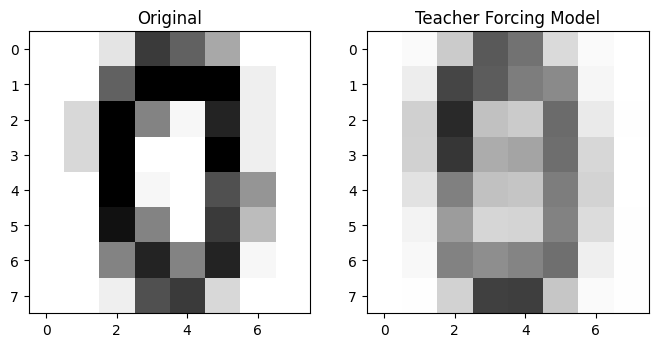

In [ ]:
# Free-running reconstruction:
# each pixel is fed back the model's own previous predictions

# Complete suggestion from Claude to implement the following block of code
# for further comparisons other than loss

@jax.jit
def reconstruct_tf(p, z):
    def predict_pixel(i, generated):
        pixel = jax.nn.sigmoid(decode_logits(p, z, generated)[:, i])
        return generated.at[:, i].set(pixel)
    return jax.lax.fori_loop(0, 64, predict_pixel, jnp.zeros((z.shape[0], 64)))

def bce(R, eps=1e-6):
    R = jnp.clip(R, eps, 1 - eps)
    return float(jnp.mean(-(X * jnp.log(R) + (1 - X) * jnp.log(1 - R))))

z = encode(params_tf, X)
R = reconstruct_tf(params_tf, z)
print("Free-running BCE:", bce(R), " MSE:", float(jnp.mean((X - R) ** 2)))

# decode from shuffled latent
# a big loss increase means the decoder really uses z
z_shuf = z[np.random.default_rng(1).permutation(len(z))]
print("Shuffled-z BCE  :", bce(reconstruct_tf(params_tf, z_shuf)))

# baseline MSE
print("Mean-image MSE  :", float(np.mean((x_data - x_data.mean(0)) ** 2)))

fig, ax = plt.subplots(1, 2, figsize=(8, 4))
ax[0].imshow(X[20].reshape(8, 8), cmap="Greys", vmin=0, vmax=1); ax[0].set_title("Original")
ax[1].imshow(R[20].reshape(8, 8), cmap="Greys", vmin=0, vmax=1); ax[1].set_title("Teacher Forcing Model")
plt.show()